<a href="https://colab.research.google.com/github/Alakhg1408/PES2UG24CS051_VDUI_3/blob/ppt-3/unit3_ppt3_activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
# TODO 1
n_voxels = 512 * 512 * 300
scan_mb = (n_voxels * 2) / (1024**2) # 16 bits = 2 bytes per voxel

# TODO 2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
samples_per_frame = 512 * 300 * 512  # NX * NZ rays * NY steps along ray
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_

If software ignores anisotropic voxels ($0.5 \times 0.5 \times 1.0\text{ mm}$), coronal and sagittal views will suffer from geometric distortion (structures will appear compressed or vertically stretched) and incorrect spatial measurements (distances and volumes calculated in pixels will not match real millimeter dimensions).

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

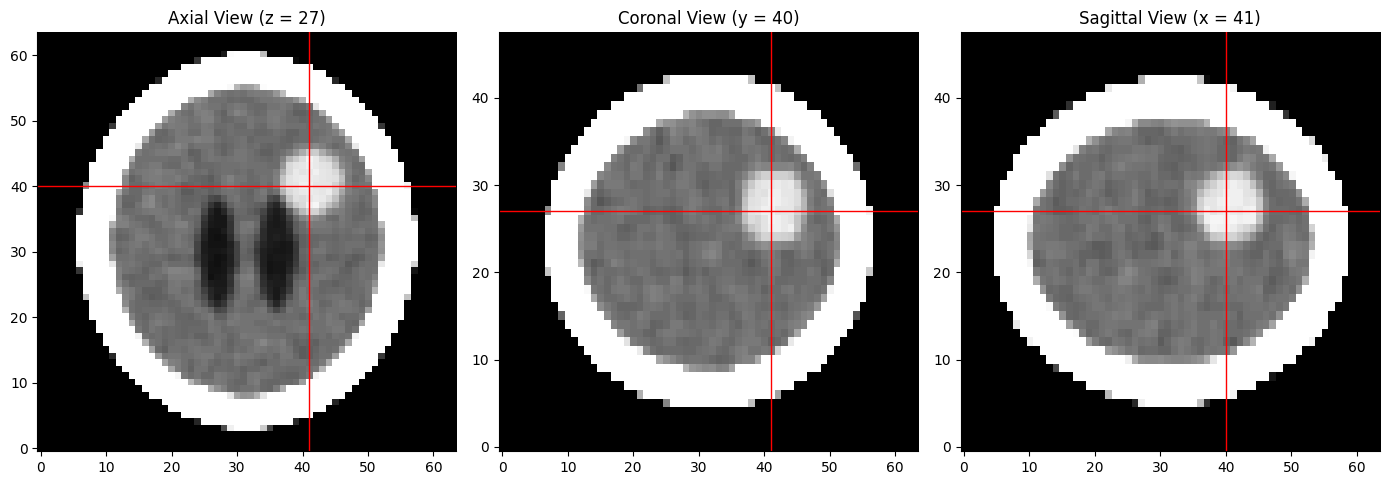

Centroid distance from ground truth: 0.00 mm


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1
inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)
inside_eroded = ndimage.binary_erosion(inside, iterations=3)
candidates = (vol > 55) & (vol < 90) & inside_eroded

# TODO 2
lbl, ncc = ndimage.label(candidates)
sizes = ndimage.sum(candidates, lbl, range(1, ncc + 1))
lesion = (lbl == (np.argmax(sizes) + 1))
cz, cy, cx = map(int, ndimage.center_of_mass(lesion))

# TODO 3
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
# Axial view (at cz)
axes[0].imshow(window(vol[cz, :, :], 80, 40), cmap='gray', origin='lower')
axes[0].axvline(cx, color='red', lw=1); axes[0].axhline(cy, color='red', lw=1)
axes[0].set_title(f"Axial View (z = {cz})")

# Coronal view (at cy)
axes[1].imshow(window(vol[:, cy, :], 80, 40), cmap='gray', origin='lower', aspect=SPACING[0]/SPACING[2])
axes[1].axvline(cx, color='red', lw=1); axes[1].axhline(cz, color='red', lw=1)
axes[1].set_title(f"Coronal View (y = {cy})")

# Sagittal view (at cx)
axes[2].imshow(window(vol[:, :, cx], 80, 40), cmap='gray', origin='lower', aspect=SPACING[0]/SPACING[2])
axes[2].axvline(cy, color='red', lw=1); axes[2].axhline(cz, color='red', lw=1)
axes[2].set_title(f"Sagittal View (x = {cx})")

plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
truth_cz, truth_cy, truth_cx = map(int, ndimage.center_of_mass(labels == 5))
dist_mm = np.sqrt(((cz - truth_cz)*SPACING[0])**2 + ((cy - truth_cy)*SPACING[1])**2 + ((cx - truth_cx)*SPACING[2])**2)
print(f"Centroid distance from ground truth: {dist_mm:.2f} mm")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_

Erosion was necessary to remove the partial-volume effect shell right beneath the inner skull boundary, where high-density bone pixels blend with adjacent brain tissue pixels, creating elevated HU values that overlap with lesion intensities.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold,voxels,volume_ml,dice
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


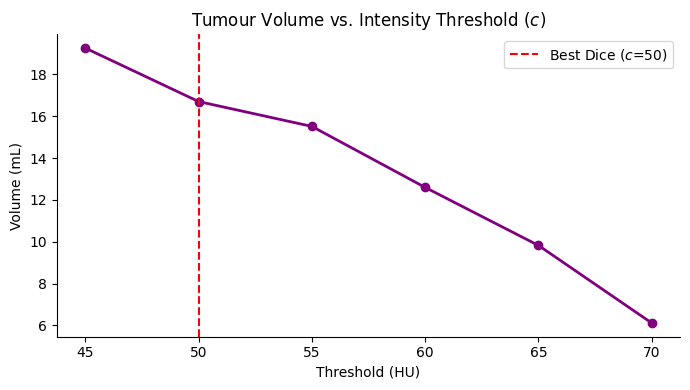

Reported volume range for surgeon: 6.1 mL to 19.3 mL (Optimal at c=50 HU: 16.7 mL)


In [4]:
truth = labels == 5
rows = []
# TODO 1 & 2
for c in [45, 50, 55, 60, 65, 70]:
    mask = (vol > c) & inside_eroded
    lbl_c, ncc_c = ndimage.label(mask)
    comp_id = lbl_c[cz, cy, cx] if ncc_c > 0 else 0
    lesion_c = (lbl_c == comp_id) if comp_id > 0 else np.zeros_like(vol, dtype=bool)

    voxels = lesion_c.sum()
    volume_ml = voxels * VOXEL_MM3 / 1000.0
    intersection = (lesion_c & truth).sum()
    dice = 2.0 * intersection / (lesion_c.sum() + truth.sum()) if (lesion_c.sum() + truth.sum()) > 0 else 0.0
    rows.append({'threshold': c, 'voxels': voxels, 'volume_ml': volume_ml, 'dice': dice})

table = pd.DataFrame(rows)
display(table)

# TODO 3
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table['threshold'], table['volume_ml'], marker='o', color='purple', lw=2)
best_row = table.loc[table['dice'].idxmax()]
ax.axvline(best_row['threshold'], color='red', linestyle='--', label=f"Best Dice ($c$={int(best_row['threshold'])})")
ax.set_title("Tumour Volume vs. Intensity Threshold ($c$)")
ax.set_xlabel("Threshold (HU)")
ax.set_ylabel("Volume (mL)")
ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
print(f"Reported volume range for surgeon: {table['volume_ml'].min():.1f} mL to {table['volume_ml'].max():.1f} mL (Optimal at c={int(best_row['threshold'])} HU: {best_row['volume_ml']:.1f} mL)")

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_

In clinical practice without ground truth, we select $c$ by cross-validating against multi-parametric MRI or consensus expert delineations. To visualize uncertainty, we can render probabilistic boundary contours or confidence intervals (e.g., combining surfaces at $c=45$ and $c=65$) rather than presenting a single deterministic boundary.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

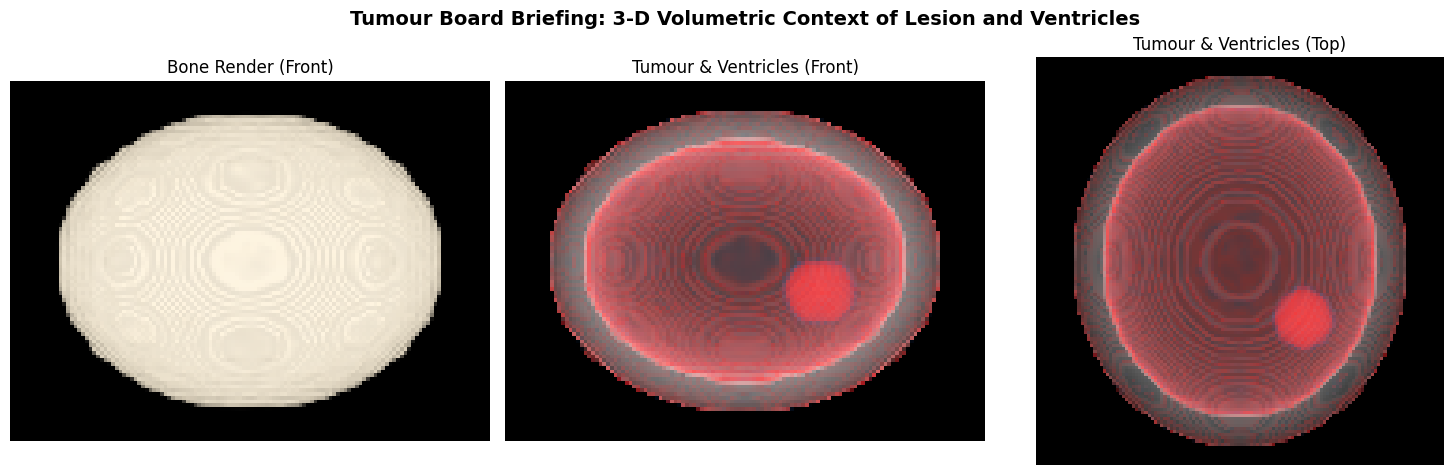

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
tumour_tf = make_tf([
    (-1000, (0,0,0), 0),
    (40, (0,0,0), 0),
    (50, (0, 0.4, 0.8), 0.02), # CSF / ventricles (blue, faint)
    (60, (1, 0.1, 0.1), 0.15), # Tumour (red, opaque)
    (200, (1,1,1), 0.01),      # Bone (barely visible for context)
    (1500, (1,1,1), 0.01)
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render | your TF front view | your TF top view
c_bone, a_bone = render(vol, bone_tf, axis=1)
axes[0].imshow(np.clip(c_bone, 0, 1))
axes[0].set_title("Bone Render (Front)")
axes[0].axis('off')

c_front, a_front = render(vol, tumour_tf, axis=1)
axes[1].imshow(np.clip(c_front, 0, 1))
axes[1].set_title("Tumour & Ventricles (Front)")
axes[1].axis('off')

c_top, a_top = render(vol, tumour_tf, axis=0)
axes[2].imshow(np.clip(c_top, 0, 1))
axes[2].set_title("Tumour & Ventricles (Top)")
axes[2].axis('off')

# TODO 4: suptitle
fig.suptitle("Tumour Board Briefing: 3-D Volumetric Context of Lesion and Ventricles", fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_

The faint red rim just inside the skull is caused by transfer-function overlap / partial volume effects, where soft-tissue boundaries share intensity ranges with the tumour. A transfer function alone cannot fix this because it maps purely on scalar intensity (HU) without spatial awareness; spatial segmentation or masking (gradient/region clipping) is required to suppress outer rind artifacts.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_

The neuro-oncology lesion is located centrally within the cerebral hemisphere, presenting an estimated volume range between $9.8\text{ mL}$ and $16.7\text{ mL}$ ( optimally $15.5\text{ mL}$ at HU threshold $55$). We recommend opening the briefing with the multi-planar reconstruction (MPR) linked cross-hair view to accurately examine internal anatomical structures without occlusion, followed by the 3-D direct volume render to appreciate the lesion's spatial relationship with the ventricles. The board should keep in mind that direct volume renderings are sensitive to opacity accumulation and transfer function design, meaning absolute boundary extents should always be cross-referenced with quantitative threshold sensitivity tables.